## R3XA Tutorial 0 - creating, plotting and saving a first basic R3XA file
First load the R3XA API python package

In [11]:
import r3xa_api as r3xa

### Header
_Contains the general information used to identify and document the dataset, such as its title, description, version, authors, and date + other optional attributes._

Creating a new R3XA file based on the `header` information

In [12]:
my_file = r3xa.R3XAFile(
    title="R3XA tutorial 1",
    description="Minimal example of a R3XA file",
    authors="JC Passieux",
    date="2026-04-02",
)

To **print a R3XA file** like `my_file`. <br>
_All the possible attributes are listed, additional attributes forbidden. Attributes with a * are required._

In [13]:
print(my_file)

R3XA File
────────────────────────────────────────
title*        : R3XA tutorial 1
description   : Minimal example of a R3XA file
version*      : 2024.7.1
authors*      : JC Passieux
date*         : 2026-04-02
repository    : None
documentation : None
license       : None
settings      : []
datasources   : []
datasets      : []


### Settings
_`settings` is a list of devices not directly generating data but describing the experimental context, including the test specimen, testing machines, equipment, and conditions used during the experiment (ex: testing machine, light, environment chamber...)._

 Creating a new `setting`, here a spot light.

In [14]:
light = r3xa.new_setting.GenericSetting(
    title='Spot light',
    description='Spotlight MultiLed QX 100% indirect - GS Vitec SN : GS01224 and GS01225',
    documentation='https://www.blinktech.com.au/wp-content/uploads/2023/10/MULTILED_QX.pdf'    
    )

To **print a** `setting` (the same holds also for `data_source` and `data_set`)

In [15]:
print(light)

GenericSetting
───────────────────────────────────────────
id*                     : jlmhmxueiryxhxodptzvygbu
kind*                   : settings/generic
title*                  : Spot light
description*            : Spotlight MultiLed QX 100% indirect - GS Vitec SN : GS01224 and GS01225
documentation           : https://www.blinktech.com.au/wp-content/uploads/2023/10/MULTILED_QX.pdf
associated_data_sources : None


**Adding a setting** `light` to the R3XA file, simply add in the list of `my_file.settings`:

In [16]:
my_file.settings += [light, ]

### Data Sources
_`data_sources` is a list of sensors or analysis tools that directly generate or calculate data, including the sensors, cameras, or analysis methods used and their characteristics._

Creating a new `data_source` of type camera

In [17]:
camera = r3xa.new_datasource.CameraDataSource(
    title="CCD Camera",
    description="",
    output_components=1,
    output_dimension="surface",
    output_units=[r3xa.unit(title="graylevel", value=1.0, unit="gl", scale=1.0)],
    manufacturer="Allied Vision Technologies (AVT)",
    model="Dolphin F-145B",
    image_size=[
        r3xa.unit(title="width", value=1392, unit="px"),
        r3xa.unit(title="height", value=1040, unit="px"),
    ]
)
print(camera)

CameraDataSource
──────────────────────────────────────
id*                : gxfrgfcsacoghfxbgkltjanp
kind*              : data_sources/camera
title*             : CCD Camera
description        : 
input_data_sets    : None
output_components* : 1
output_dimension*  : surface
output_units*      : [1.0 gl]
manufacturer       : Allied Vision Technologies (AVT)
model              : Dolphin F-145B
documentation      : None
image_size*        : [1392 px, 1040 px]
field_of_view      : None
image_scale        : None
focal_length       : None
lens               : None
filter             : None
aperture           : None
exposure           : None
standoff_distance  : None
uncertainty        : None


**Adding the data_source** `camera` to the list of data_sources of R3XA file `my_file`

In [18]:
my_file.data_sources += [camera, ]

### Data sets
_`data_sets` is a list of datasets describing how and where the data are stored, their unit and format, linking the data files to the source that produced them and, when needed, to their time references._

Creating a new `data_set` example as a list of digital images

In [19]:
image_files = ['img_0000.tif', 'img_0001.tif', 'img_0002.tif']
timestamps = [1.0, 1.5, 2]

images = r3xa.new_dataset.ListDataSet(
    title="visible images",
    description="my graylevel images",
    path="images/",
    file_type="image/tiff",
    data_sources=[camera.id],
    time_reference=r3xa.unit(title="time_reference", value=0.0, unit="s", scale=1.0),
    timestamps=timestamps,
    data=image_files,
)
print(images)


ListDataSet
───────────────────────────────────
id*             : vmivvlvpquxwlopahwoxfgtx
kind*           : data_sets/list
title*          : visible images
description*    : my graylevel images
path            : images/
file_type*      : image/tiff
data_sources*   : [gxfrgfcsacoghfxbgkltjanp]
time_reference* : 0.0 s
keywords        : None
timestamps*     : [1.0, 1.5, 2]
data*           : [img_0000.tif, img_0001.tif, img_0002.tif]


Then add the dataset `images` to the list of data_sets of r3xa file `my_file`

In [20]:
my_file.data_sets += [images, ]

### Printing and Plotting R3XA files
To print a full R3XA file, just type `print(my_file)`

In [21]:
print(my_file)

R3XA File
────────────────────────────────────────
title*        : R3XA tutorial 1
description   : Minimal example of a R3XA file
version*      : 2024.7.1
authors*      : JC Passieux
date*         : 2026-04-02
repository    : None
documentation : None
license       : None
settings      : [Spot light]
datasources   : [CCD Camera]
datasets      : [visible images]


To plot a R3XA file as a flowchart, type `plot()`

[Case(id='jlmhmxueiryxhxodptzvygbu', name='Spot light', parent_ids=[], color='#c4894f', text_color='white'), Case(id='gxfrgfcsacoghfxbgkltjanp', name='CCD Camera', parent_ids=[], color='#bf0040', text_color='white'), Case(id='vmivvlvpquxwlopahwoxfgtx', name='visible images', parent_ids=['gxfrgfcsacoghfxbgkltjanp'], color='#038181', text_color='white')]


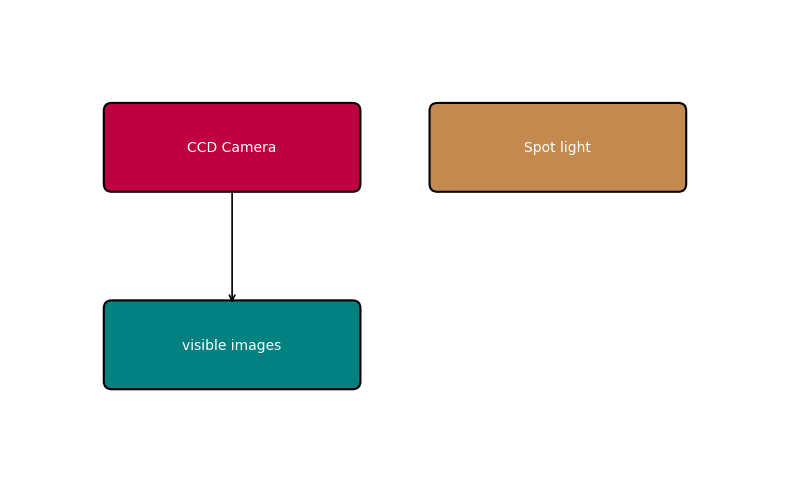

In [22]:
my_file.plot()

### Saving R3XA files

To **save a R3XA file** to the disk

In [23]:
my_file.save('save/my_first_r3xa_file.json')

WindowsPath('save/my_first_r3xa_file.json')